In [1]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [2]:
lambda_qcd = 0.241 #GeV
conv_fmGeV = 5.068 # fm to GeV^-1
d = 0.54 * conv_fmGeV # GeV-1 
A = 197 # 197 for Au beam, 208 for Pb beam
conv_mbGeV2 = 2.56819

def RA(A):
    return (1.12 * A**(1/3) - 0.86*A**(-1/3))*conv_fmGeV # return in GeV^-1

def rhoA(z, bt, A): # Woods-Saxon distribution # GeV-1 
    ra = RA(A)
    n = 3.0/(4.0 * np.pi * RA(A)**3) * 1.0/(1.0 + (np.pi * d/RA(A))**2)
    B = (np.sqrt(bt**2 + z**2) - ra)/d
    rhoA = n / (1 + np.exp(B))
    return rhoA

# Woods-Saxon distribution T_A: rhoA integrated over z
def get_TA(bt, A): 
    TA = integrate.quad(rhoA, -999.0, 999.0, args = (bt, A))
    return TA[0]

def dipA(r, bt, A, Qs02, gamma, e_c, sigma0_2): # dipole nucleus
    sigma0_2 = sigma0_2 * 2.56819 # converted to 1/GeV2
    #n = woods_saxon_norm(A)
    #test = integrate.quad(lambda b: 2.0*np.pi*b*get_TA(b, A), 0, np.inf)
    #assert np.isclose(test[0], 1.0, atol=1e-3), "Thickness function not normalized to 1.0"
    TA = get_TA(bt, A) 
    B = A * TA * (sigma0_2)*((r**2)*(Qs02))**gamma
    C = 1/(r*lambda_qcd) + e_c * np.exp(1)
    N = 1 - np.exp(-B/4 * np.log(C))
    #print(TA)
    return N

In [3]:
#load initial condition parameters
#ic_qs, ic_ec, ic_c2, ic_sigma02 = np.loadtxt("../data/hm2013/mv_param.dat", unpack = True)
ic_qs, ic_ec, ic_c2, ic_sigma02 = np.loadtxt("../data/dipole/posteriorsamples_100_LOmvefit.dat", unpack = True)


In [4]:
from scipy.optimize import fsolve

def qs_func(r, bk_interp, y):
    #x0 = 1.0
    #xbj = 0.00001 # 10⁻5
    #y_int = np.log(x0/x)
    func = bk_interp(y, r) - (1 - np.exp(-1/2))
    return func

def solve_qs(bk_interp, y):
    r_guess = 0.20
    r_solution = fsolve(qs_func, r_guess, args = (bk_interp, y))
    qs_solution = 2/r_solution**2

    if qs_solution < 0 or np.isnan(qs_solution):
        raise ValueError("Nan or negative Qs solution found.")
    
    if bk_interp(y, np.sqrt(2/qs_solution)) > 0.39347 or bk_interp(y, np.sqrt(2/qs_solution)) < 0.39345:
        raise ValueError("Qs solution does not satisfy the condition N(r=√(2/$Q_s^2$), y) ≈ 1 - exp(-1/2).")

    return qs_solution

Reading BK file: ../data/dipole/initial_run/bk_samplefrommvefit.dat
Qs from BK:  [0.27643671]
### y =  0.0
[5.44264820e-02 1.00000251e+00 5.85249097e+01 9.99962937e-01]
Qs from BK:  [0.27876299]
### y =  0.081
[5.29376699e-02 9.94170170e-01 7.41313282e+01 9.71949595e-01]
Qs from BK:  [0.28134087]
### y =  0.162
[5.06431987e-02 9.87921970e-01 9.99996078e+01 9.57304917e-01]
Qs from BK:  [0.28396581]
### y =  0.242
[5.23501232e-02 9.86464283e-01 9.99999992e+01 9.16915242e-01]
Qs from BK:  [0.28666258]
### y =  0.323
[ 0.08601592  1.01714695 18.72324665  0.77923683]
Qs from BK:  [0.28953418]
### y =  0.404
[ 0.09432695  1.02031796 15.23158855  0.75107542]
Qs from BK:  [0.29244085]
### y =  0.485
[ 0.10180072  1.02234273 13.09492305  0.72799213]
Qs from BK:  [0.29554035]
### y =  0.566
[ 0.10884048  1.02374906 11.55008148  0.7096647 ]
Qs from BK:  [0.29874079]
### y =  0.646
[ 0.11571521  1.02473784 10.39134581  0.69323898]
Qs from BK:  [0.30210615]
### y =  0.727
[0.12246388 1.02542107 9.4

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


### y =  8.0
[1.57413748 0.96177422 2.17333482 0.47194756]


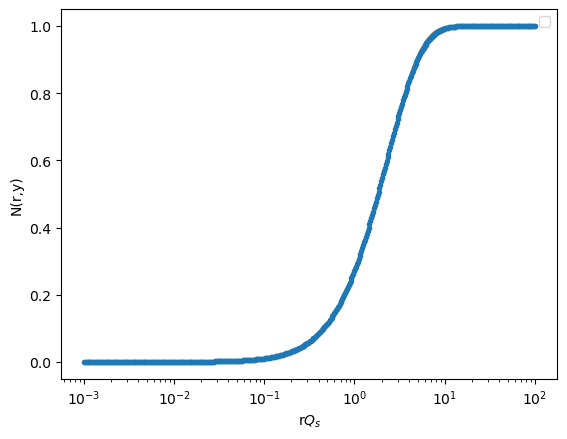

In [5]:
bk_file = "../data/dipole/initial_run/bk_samplefrommvefit.dat"
#bk_file = '../data/nucleus/posterior/0/ic_197_0.dat'
#bk_file = '../data/nucleus/ic_197_0.dat'
#bk_file = "../data/hm2013/mv_bk.dat"
#bk_file = "../data/hm2013/Au/bk/glauber_mv1_0"
BKinterpolator = dipole.BKDipole(bk_file)
#init = [1.0, 0.8, 1.0, 1.0]
init = [1.0, 1.0, 1.0, 0.3]
lbounds = [0.001, 0.1, 1.0/np.exp(1), 0.1]
ubounds = [10.0, 100.0, 100.0, 10.0]
grid_size = 100
y_max = 8.0
y_array = np.linspace(0, y_max, grid_size)
rqsgrid = np.logspace(-3, 2, 500)
allr = np.logspace(-3,2, 200)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function
func_qs2 = lambda yy,rr: BKinterpolator.N(yy,rr)
fit_params_array = np.ones((len(y_array), 4))
i = 0
file_params = open("test.dat", "w")
for y in y_array:
    # if i == 0:
    #     initial = init
    # else:
    #     initial = fit_params_array[i-1, :]
    Qs2 = solve_qs(func_qs2, y)
    print("Qs from BK: ", Qs2)
    #print("Check if Qs is correct: ", func_qs2(y, np.sqrt(2/Qs2))) 
    r = rqsgrid/np.sqrt(Qs2)
    #print('r=',r)
    minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds)
    out = minimizer.fit_ls()
    fit_params = out.x
    # if y > 2 and y < 4:
    #     fit_params[3] = 0.6
    fit_params_array[i, :] = fit_params
    
    fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    if y == y_max:
        rqs2_grid_ext = np.logspace(-4, 2, 600)
        r_grid_ext = rqs2_grid_ext/np.sqrt(Qs2)
        fit_ext = [minimizer.Ff(rr, fit_params[0], fit_params[1], fit_params[2], fit_params[3]) for rr in r_grid_ext]
        data_ext = np.exp(Nyr(y,r_grid_ext))
        #a = np.abs(np.exp(fit_func)-np.exp(Nyr(y,r)))/np.exp(Nyr(y,r))
        #a = np.abs(fit_ext - data_ext)/data_ext
        #plt.plot(rqs2_grid_ext, a, '--', color = 'gray')        
        plt.plot(rqsgrid, np.exp(Nyr(y,r)), '-', color = 'gray')
        plt.plot(rqsgrid, np.exp(fit_func), '.')
        plt.xscale('log')
        #plt.yscale('log')
        #plt.xlim(1e-1, 1e1)
        plt.legend()
        plt.xlabel('r$Q_s$')
        plt.ylabel('N(r,y)')
    # if y == 0 or y == 0.12:
    #     fit_params_array[i, :] = [ic_qs[0], 1.0, ic_ec[0], 1.0]
    #     fit_params_array[i, 0] = 197 * get_TA(0, A) * ic_sigma02[0] * conv_mbGeV2 * ic_qs[0]
    #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    print('### y = ', np.round(y,3))
    print(fit_params_array[i, :] )
    # if y > 1:
    #init = fit_params
    i += 1

with file_params:
    file_params.write("# Parameter file of fit of dipole from {}".format(bk_file) + "\n")
    file_params.write("# y ranges from 0 to {} in {} steps".format(y_max, grid_size) + "\n")
    file_params.write("# Columns: y, Qs2, gamma, ec, p" + "\n")
    for j in range(len(y_array)):
        file_params.write("{: .6e} {: .6e} {: .6e} {: .6e} {: .6e}\n".format(y_array[j], fit_params_array[j,0], fit_params_array[j,1], fit_params_array[j,2], fit_params_array[j,3]))

In [6]:
# #bk_file = "../data/dipole/initial_run/bk_samplefrommvefit.dat"
# #bk_file = '../data/nucleus/posterior/0/ic_197_0.dat'
# bk_file = '../data/nucleus/ic_197_0.dat'
# #bk_file = "../data/hm2013/mv_bk.dat"
# #bk_file = "../data/hm2013/Au/bk/glauber_mv1_0"
# BKinterpolator = dipole.BKDipole(bk_file)
# #init = [1.0, 0.8, 1.0, 1.0]
# init = [1.0, 1.0, 1.0, 0.6]
# lbounds = [0.01, 0.1, 1.0/np.exp(1), 0.01]
# ubounds = [10.0, 100.0, 100.0, 10.0]
# grid_size = 8
# y_max = 8.0
# y_array = np.linspace(0, y_max, grid_size)
# #rqsgrid2 = np.sort(np.concatenate((np.logspace(-4, 2, 300), np.logspace(0, 2, 100))))
# rqsgrid2 = np.logspace(-2,2, 400)
# allr = np.logspace(-3,2, 200)
# Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function
# func_qs2 = lambda yy,rr: BKinterpolator.N(yy,rr)
# fit_params_array = np.ones((len(y_array), 4))
# i = 0
# file_params = open("test.dat", "w")
# for y in y_array:
#     # if i == 0:
#     #     initial = init
#     # else:
#     #     initial = fit_params_array[i-1, :]
#     Qs2 = solve_qs(func_qs2, y)
#     print("Qs from BK: ", Qs2)
#     #print("Check if Qs is correct: ", func_qs2(y, np.sqrt(2/Qs2))) 
#     r = rqsgrid2/np.sqrt(Qs2)
#     #print('r=',r)
#     minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds, lsmethod='trf')
#     out = minimizer.fit_ls()
#     fit_params = out.x
#     # if y > 2 and y < 4:
#     #     fit_params[3] = 0.6
#     fit_params_array[i, :] = fit_params
    
#     fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
#     if y == y_max:
#         #rqs2_grid_ext = np.logspace(-3, 2, 600)
#         #r_grid_ext = rqs2_grid_ext/np.sqrt(Qs2)
#         fit_ext = [minimizer.Ff(rr, fit_params[0], fit_params[1], fit_params[2], fit_params[3]) for rr in r_grid_ext]
#         #data_ext = np.exp(Nyr(y,r_grid_ext))
#         #a = np.abs(np.exp(fit_func)-np.exp(Nyr(y,r)))/np.exp(Nyr(y,r))
#         #a = np.abs(fit_ext - data_ext)/data_ext
#         #plt.plot(rqs2_grid_ext, a, '--', color = 'gray')
#         b =   np.abs(fit_ext - data_ext)/data_ext #np.abs(np.exp(fit_func)-np.exp(Nyr(y,r)))/np.exp(Nyr(y,r))
#         # plt.plot(rqs2_grid_ext, a, '-', label = 'min 1e-2')
#         # plt.plot(rqs2_grid_ext, b, '--', label = 'min 1e-3')
#         #plt.plot(rqsgrid2, b, '.', label='y = '+str(np.round(y,3)))
#         plt.plot(rqsgrid2, np.exp(Nyr(y,r)), '-', color = 'gray')
#         plt.plot(rqsgrid2, np.exp(fit_func), '.')
#         plt.xscale('log')
#         #plt.yscale('log')
#         #plt.xlim(1e-1, 1e1)
#         plt.legend()
#         plt.xlabel('r$Q_s$')
#         #plt.ylabel('N(r,y)')
#         plt.ylabel('relative error')
#     # if y == 0 or y == 0.12:
#     #     fit_params_array[i, :] = [ic_qs[0], 1.0, ic_ec[0], 1.0]
#     #     fit_params_array[i, 0] = 197 * get_TA(0, A) * ic_sigma02[0] * conv_mbGeV2 * ic_qs[0]
#     #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
#     print('### y = ', np.round(y,3))
#     print(fit_params_array[i, :] )
#     # if y > 1:
#     #init = fit_params
#     i += 1
# # Reading BK file: ../data/nucleus/ic_197_0.dat
# # Qs from BK:  [0.85962629]
# # ### y =  0.0
# # [0.55646476 1.14064775 1.26949458 0.6       ]
# # Qs from BK:  [0.93098494]
# # ### y =  0.75
# # [0.54319158 1.07966787 2.76421589 0.59999998]
# # Qs from BK:  [1.02744562]
# # ### y =  1.5
# # [0.62919089 1.05035953 2.73634863 0.59999992]
# # Qs from BK:  [1.15407817]
# # ### y =  2.25
# # [0.73634107 1.02665086 2.64525698 0.59999996]
# # Qs from BK:  [1.31660313]
# # ### y =  3.0
# # [0.85976087 1.00552759 2.63016921 0.59537279]
# with file_params:
#     file_params.write("# Parameter file of fit of dipole from {}".format(bk_file) + "\n")
#     file_params.write("# y ranges from 0 to {} in {} steps".format(y_max, grid_size) + "\n")
#     file_params.write("# Columns: y, Qs2, gamma, ec, p" + "\n")
#     for j in range(len(y_array)):
#         file_params.write("{: .6e} {: .6e} {: .6e} {: .6e} {: .6e}\n".format(y_array[j], fit_params_array[j,0], fit_params_array[j,1], fit_params_array[j,2], fit_params_array[j,3]))

Qs from BK:  [1.61652664]


Text(0.5, 1.0, 'y=8')

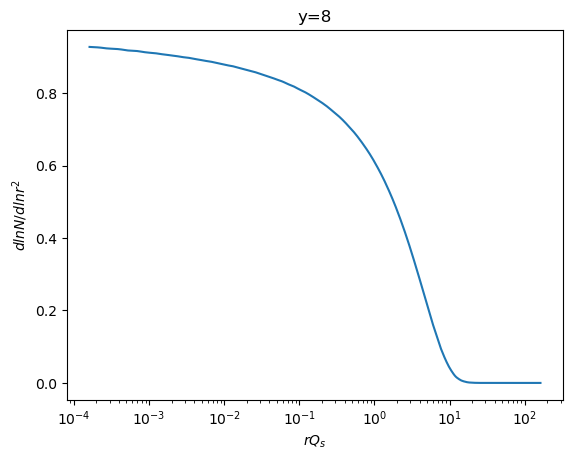

In [7]:
rqsgrid = np.logspace(-6, 2, 400)
y = 8
Qs2 = solve_qs(func_qs2, y)
print("Qs from BK: ", Qs2)
r = np.logspace(-4, 2, 400)
nvals = np.ones(len(r))
for i in range(len(r)):
    nvals[i] = BKinterpolator.N(y, r[i])
gamma_eff = np.gradient(np.log(nvals), np.log(r**2))
plt.plot(r*Qs2, gamma_eff, label=f"y={y}")
plt.xscale('log')
plt.xlabel('$rQ_s$')
plt.ylabel('$d ln N / d ln r^2$')
plt.title(f'y={y}')

## Get Fourier transform

In [8]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(y,k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def log_S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

Reading BK file: ../data/dipole/initial_run/bk_samplefrommvefit.dat


[1.00000000e-02 1.20679264e-02 1.45634848e-02 1.75751062e-02
 2.12095089e-02 2.55954792e-02 3.08884360e-02 3.72759372e-02
 4.49843267e-02 5.42867544e-02 6.55128557e-02 7.90604321e-02
 9.54095476e-02 1.15139540e-01 1.38949549e-01 1.67683294e-01
 2.02358965e-01 2.44205309e-01 2.94705170e-01 3.55648031e-01
 4.29193426e-01 5.17947468e-01 6.25055193e-01 7.54312006e-01
 9.10298178e-01 1.09854114e+00 1.32571137e+00 1.59985872e+00
 1.93069773e+00 2.32995181e+00 2.81176870e+00 3.39322177e+00
 4.09491506e+00 4.94171336e+00 5.96362332e+00 7.19685673e+00
 8.68511374e+00 1.04811313e+01 1.26485522e+01 1.52641797e+01
 1.84206997e+01 2.22299648e+01 2.68269580e+01 3.23745754e+01
 3.90693994e+01 4.71486636e+01 5.68986603e+01 6.86648845e+01
 8.28642773e+01 1.00000000e+02]


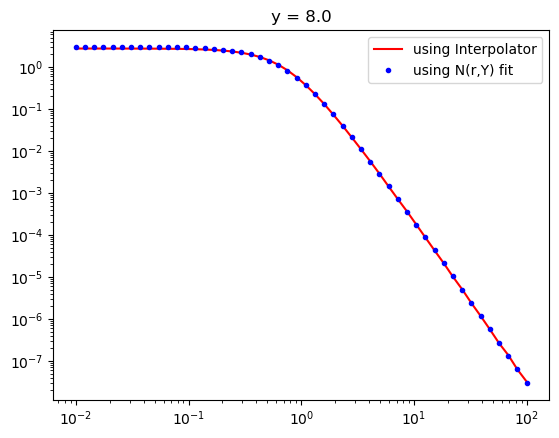

In [9]:
fit_params = fit_params_array[grid_size-1] # last rapidity
k = np.logspace(-2, 2, 50)
print(k)
Sk = S(y_max,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using N(r,Y) fit', color='blue')
plt.title(f'y = {y_max}')
plt.legend()
plt.xscale('log')
plt.yscale('log')

In [10]:
# from matplotlib import rc
# plt.rcdefaults()
# rc('text', usetex=True)
# plt.rcParams["font.family"] = "serif"
# plt.rcParams["mathtext.fontset"] = "cm"

/tmp/ipykernel_732831/1442657786.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


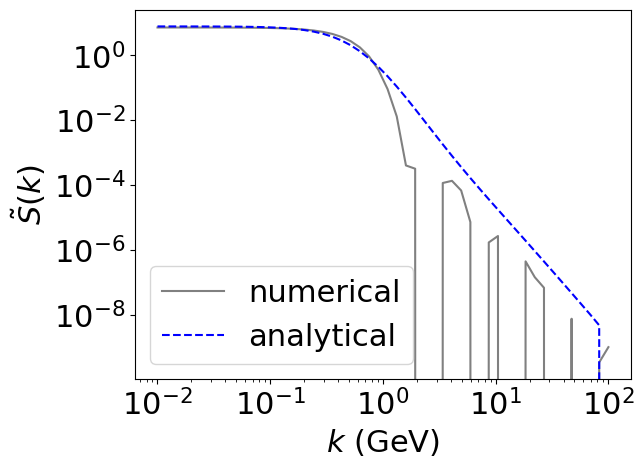

In [24]:
fit_params = fit_params_array[33]
#print("Fit params at y=0: ", fit_params)
#fit_params = [0.11968468, 0.6, 4.77656673, 1.5]
k = np.logspace(-2, 2, 50)
Sk = S(0,k)
Sk2 = log_S2(k, fit_params)
Sk2 = np.nan_to_num(Sk2, nan = -99999)
plt.plot(k, Sk, label='numerical', color='gray')
plt.plot(k, 10**Sk2, '--', label = 'analytical', color='blue')
# plt.title('y = ')
plt.xlabel("$k$ (GeV)", fontsize = 22)
plt.ylabel(r"$\tilde{S}(k)$",  fontsize = 22)
plt.xticks(fontsize = 22)
plt.yticks(fontsize = 22)
plt.legend( fontsize = 22)
plt.xscale('log')
plt.yscale('log')


In [12]:
Sk

array([ 7.23282578e+00,  7.23711955e+00,  7.23455147e+00,  7.23235801e+00,
        7.23081212e+00,  7.21935349e+00,  7.21469880e+00,  7.20306403e+00,
        7.18566439e+00,  7.16040014e+00,  7.12575667e+00,  7.07605566e+00,
        7.00386731e+00,  6.89979286e+00,  6.75038154e+00,  6.53852240e+00,
        6.24178659e+00,  5.83361516e+00,  5.28628707e+00,  4.57959772e+00,
        3.71573242e+00,  2.74037641e+00,  1.75874031e+00,  9.21995618e-01,
        3.60200490e-01,  9.17916661e-02,  1.31080008e-02,  4.03498374e-04,
        3.20541050e-04, -4.45444595e-05, -8.33314167e-06,  1.16204667e-04,
        1.35631281e-04,  6.82281015e-05,  7.27118405e-06, -4.24990739e-06,
        1.70776817e-06,  2.69651426e-06, -2.80553473e-07, -6.75893669e-07,
        4.45637978e-07,  1.44888032e-07,  6.84393789e-08, -1.88557525e-08,
       -8.40890166e-09,  7.59304548e-09, -5.36326606e-09, -1.35817492e-09,
        3.41544884e-10,  1.01063642e-09])

[ 0.85950407  0.85949364  0.85952947  0.85950084  0.85942959  0.85935552
  0.8592767   0.85917954  0.85906065  0.85891805  0.85874644  0.85853962
  0.85829052  0.85799048  0.85762909  0.85719378  0.85666946  0.85603791
  0.85527721  0.85436094  0.85325729  0.85192794  0.85032673  0.84839808
  0.84607501  0.84327686  0.83990649  0.83584687  0.83095706  0.82506727
  0.81797302  0.80942799  0.79913551  0.78673825  0.77180578  0.75381968
  0.73215556  0.70606131  0.67463109  0.6367739   0.59117569  0.5362539
  0.47010261  0.39042659  0.29446208  0.17888161  0.03967995 -0.12796179
 -0.32983676 -0.5728975  -0.86545622 -1.21735465 -1.63991647 -2.14486352
 -2.73823237 -3.39053569 -3.95098149 -4.25230195 -4.41419443 -4.54994946
 -4.68121806 -4.81037736 -4.93799133 -5.06441511 -5.18991055 -5.31467723
 -5.4388709  -5.56261539 -5.68601098 -5.8091402  -5.93207223 -6.05486609
 -6.17757321 -6.30023934 -6.42290618 -6.54561258 -6.66839563 -6.79129146
 -6.91433597 -7.03756541 -7.16101681 -7.28472839 -7.

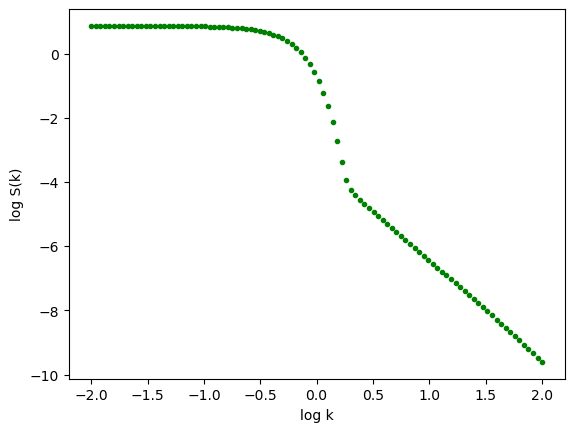

In [13]:
import pandas as pd
k_grid_size = 100#500
log_k_grid = np.linspace(-2, 2, k_grid_size)
log_Sk2 = log_S2(10**log_k_grid, fit_params)
plt.plot(log_k_grid, log_Sk2, '.',label='using fit at y=0.0', color='green')
plt.xlabel('log k')
plt.ylabel('log S(k)')
print(log_Sk2)

In [14]:
y_array_repeat = np.repeat(y_array, k_grid_size)
log_k_min = -2
log_k_max = 2
log_k_all = []
log_Sk2_all = []



for i in range(len(y_array)):
    fit_params = fit_params_array[i, :]
    log_k_grid = np.linspace(log_k_min, log_k_max, k_grid_size)
    log_Sk2 = log_S2(10**log_k_grid, fit_params)
    log_k_all.extend(log_k_grid)
    log_Sk2_all.extend(log_Sk2)

data = {'y': y_array_repeat, 'log10_k':log_k_all, 'log10_S(k)':log_Sk2_all}
df = pd.DataFrame(data)
print(np.shape(y_array_repeat))
print(np.shape(log_k_all))
print(np.shape(log_Sk2_all))

/tmp/ipykernel_732831/1442657786.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


(10000,)
(10000,)
(10000,)


Text(0.5, 0, 'y')

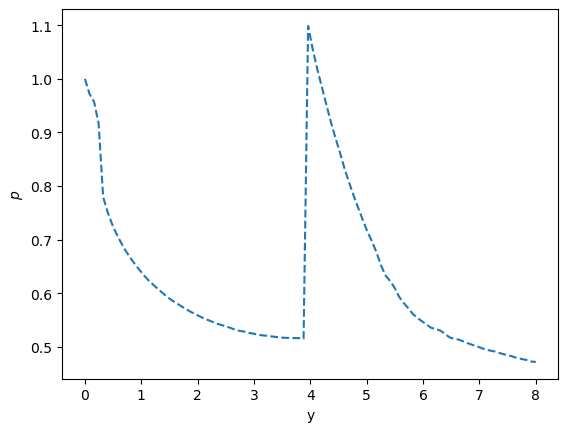

In [15]:
plt.plot(y_array, fit_params_array[:,3], '--')
plt.ylabel('$p$')
plt.xlabel('y')

In [16]:
#y = fit_params_array[:,1]
x = fit_params_array[:,1]

Text(0.5, 0, 'y')

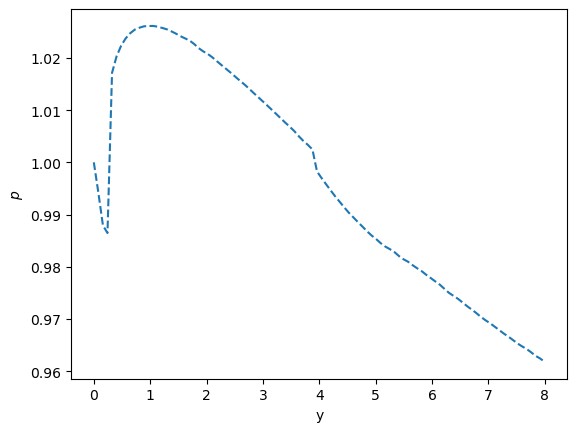

In [17]:
plt.plot(y_array, fit_params_array[:,1], '--')
plt.ylabel('$p$')
plt.xlabel('y')

In [18]:
# csv_file = '../data/hm2013/SK_data.csv'
csv_file = "/home/caaucasu/sidis_fit/data/dipole/parametrization2/Sk_fit/10e-2min/2Dft_0.csv"
comments = [ ##'## Generated from BK dipole with initial condition (arXiv: 1309.6963): MV model, Q_s0^2 = 0.104 GeV^2, \gamma = 1, coefficient of E inside Log is 1',
            f'## Fitted to BK evolved dipoles with initial condition: MVe model, Q_s0^2 = {ic_qs[i]} GeV^2, \gamma = 1, coefficient of E inside Log is {ic_ec[i]}',
                   '## Fitted to file {0}'.format(bk_file),
                   '## Note definition of log S(k): log_S(k) = log10 S(k) = log10 [ \int r dr J0(k r) (1 - N(r)) ]',
                   '## log10 k grid ranges from {0} to {1} with {2} points'.format(log_k_min, log_k_max, k_grid_size),
                   '## y grid ranges from 0 to {0} with {1} points'.format(y_max, grid_size),]

save_files = True
with open(csv_file, 'w') as f:
    for comment in comments:
        f.write(comment + '\n')
df.to_csv(csv_file, index=False, sep = ' ', columns=['y', 'log10_k', 'log10_S(k)'], mode='a', float_format='%.6e') if save_files else None

In [19]:
# import difflib

# file1 = "/home/caaucasu/sidis_fit/data/hm2013/2Dft_dipole_orig.csv"
# file2 = "/home/caaucasu/sidis_fit/data/hm2013/SK_data.csv"
# # Source - https://stackoverflow.com/a/19007888
# # Posted by Robᵩ, modified by community. See post 'Timeline' for change history
# # Retrieved 2026-05-15, License - CC BY-SA 4.0

# with open("/home/caaucasu/sidis_fit/data/hm2013/2Dft_dipole_orig.csv", 'r') as file1:
#     with open("/home/caaucasu/sidis_fit/data/hm2013/SK_data.csv", 'r') as file2:
#         same = set(file1).difference(file2)

# same.discard('\n')

# with open('some_output_file.txt', 'w') as file_out:
#     for line in same:
#         file_out.write(line)

